# 30 · Failure analysis, timing boundaries, and a shared service

Connect the previous five chapters to one system: locate retrieval versus ranking failures per query, separate timing stages, and verify serving against offline results document by document.

**Predict first:** Can average NDCG improve while some queries move from a first-position hit to no hit? Why might HTTP wall time exceed tabulated model-inference time?

Use existing per-query records for all 300 queries. Do not tune from failure analysis and still call the result an independent test.

**Navigation:** [Previous](29_Search_Fusion_Ranking.ipynb) · [Integrated experiment](17_Search_Experiments.ipynb)

> **English companion.** All instructional Markdown is translated. Experiment code, Chinese language examples, execution counts, and saved outputs remain as in the source edition; historical output text may therefore be Chinese. The initial setup cell anchors the working directory and Python import path for this companion's deeper folder; it does not change the experiment. Saved outputs are historical evidence, not a new run. Run from the top after preparing the required data and models.

In [ ]:
# English companions live one directory deeper; keep the original experiment code unchanged.
from pathlib import Path as _TranslationPath
import os as _translation_os
import sys as _translation_sys
_translation_root = next((p for p in [_TranslationPath.cwd(), *_TranslationPath.cwd().parents]
                          if (p / "reclab").is_dir()), None)
if _translation_root is None:
    raise RuntimeError("Open this notebook from inside the Search Recommendation Ads Lab checkout.")
_translation_os.chdir(_translation_root)
if str(_translation_root) not in _translation_sys.path:
    _translation_sys.path.insert(0, str(_translation_root))


In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / 'reclab').exists(): root = root.parent
os.chdir(root); sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from reclab.search_lessons import context, query_vectors, score_query, labels
from reclab.search import BM25, rrf
from reclab.retrieval import topk, metrics
ctx = context()
print('Shared search run:', ctx['receipt']['run_id'])

Shared search run: 20261030T124927-d1467622


## 1. Averages hide a distribution of wins and losses

Linear reranking's average gain over BM25 does not benefit every query. Count paired query differences and plot their distribution, including regressions rather than only successes. Distinguish exact zeros from tiny floating-point differences.

300 queries: wins/ties/losses 63 211 26


,qid,bm25,linear,delta
223,660,1.000000,0.000000,-1.000000
139,303,0.630930,0.000000,-0.630930
76,1303,1.000000,0.430677,-0.569323
7,1024,1.000000,0.500000,-0.500000
264,830,0.386853,0.000000,-0.386853
226,690,0.386853,0.000000,-0.386853
105,163,1.000000,0.630930,-0.369070
177,507,1.000000,0.630930,-0.369070


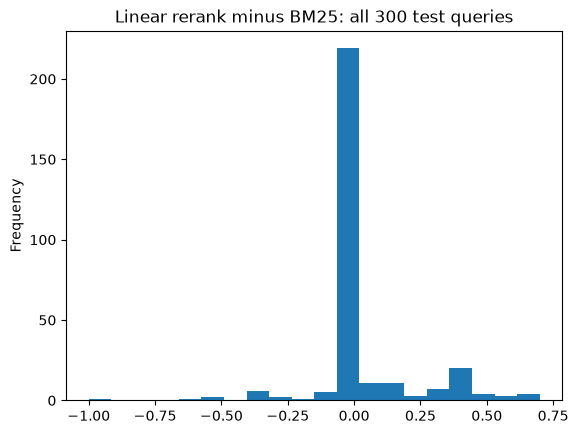

In [2]:
rows=[]
for r in ctx['per_query']:
    a=r['metrics']['bm25']['ndcg@10']; b=r['metrics']['linear_rerank']['ndcg@10']
    rows.append({'qid':r['qid'],'bm25':a,'linear':b,'delta':b-a})
errors=pd.DataFrame(rows)
print('300 queries: wins/ties/losses',int((errors.delta>1e-10).sum()),int((errors.delta.abs()<=1e-10).sum()),int((errors.delta < -1e-10).sum()))
display(errors.sort_values('delta').head(8))
errors.delta.plot.hist(bins=20,title='Linear rerank minus BM25: all 300 test queries');plt.show()

## 2. Was the target lost during retrieval or demoted in ranking?

For the eight fixed queries with the worst TinyBERT degradation, recompute the same fused top 20. A target absent from top 20 is a candidate-retrieval failure; present in top 20 but outside top 10 is a ranking problem. Judge each positive separately when both occur. For multi-positive queries, the coarse classification below asks whether at least one relevant item remains in candidates/top 10; it is not fine-grained attribution.

In [3]:
failure_ids=[r['qid'] for r in ctx['result']['failures']]
failure_vectors=query_vectors(failure_ids); diagnostics=[]
by_id={r['qid']:r for r in ctx['per_query']}
for q,v in zip(failure_ids,failure_vectors):
    candidates=topk(score_query(q,v)[2],20); truth=ctx['truth']['test'][q]
    diagnostics.append({'qid':q,'relevant_in_candidates20':len(set(candidates)&truth), 'known_relevant':len(truth),
                        'hybrid_ndcg10':by_id[q]['metrics']['hybrid_rrf']['ndcg@10'],
                        'tinybert_ndcg10':by_id[q]['metrics']['tinybert_rerank']['ndcg@10']})
display(pd.DataFrame(diagnostics))
print('Local ctx contains query text for inspection; raw text is not saved to Git.')

/Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,qid,relevant_in_candidates20,known_relevant,hybrid_ndcg10,tinybert_ndcg10
0,1363,1,1,0.333333,0.000000
1,659,1,1,1.000000,0.000000
2,660,1,1,0.315465,0.000000
3,70,2,2,0.624051,0.000000
4,94,1,1,1.000000,0.000000
5,785,1,1,0.000000,0.000000
6,743,1,1,0.630930,0.386853
7,124,1,1,1.000000,0.430677


Local ctx contains query text for inspection; raw text is not saved to Git.


## 3. State timing boundaries before reporting numbers

Formal tables include query tokenization/encoding, retrieval, fusion, and reranking; exclude model loading, indexing, disk, and HTTP. The index chapter times only indexing operations. API-reported time also differs from client HTTP wall time. Five repetitions of one warm query show jitter, not system capacity or production QPS.

Call the existing service on port 18580 without starting a second server or taking over Jupyter. If unavailable, run `./lab.sh up` as described in the README.

In [4]:
import json, time, urllib.request
base='http://127.0.0.1:18580'
def call_search(query,method):
    request=urllib.request.Request(base+'/api/search',data=json.dumps({'query':query,'method':method,'limit':10}).encode(),headers={'Content-Type':'application/json'})
    with urllib.request.urlopen(request,timeout=90) as response: return json.load(response)
qid=ctx['per_query'][0]['qid']; query=ctx['queries'][qid]
call_search(query,'hybrid_rrf')  # explicit warmup, not included below
latency=[]
for _ in range(5):
    start=time.perf_counter(); answer=call_search(query,'hybrid_rrf'); wall=(time.perf_counter()-start)*1000
    latency.append({'http_wall_ms':wall,'reported_search_ms':answer['latency_ms']})
display(pd.DataFrame(latency))

,http_wall_ms,reported_search_ms
0,18.029292,11.091667
1,16.898375,11.355250
2,17.979375,11.189958
3,16.962208,10.923458
4,16.424583,10.975125


## 4. Compare API and offline documents exactly

For the same run_id, query, and method, top-10 document IDs must match in order. Similar quality scores do not prove that serving loaded the correct model. New arbitrary queries have no qrels, so the service returns documents and ranking scores without invented NDCG.

In [5]:
expected=by_id[qid]
checks=[]
for method in ['bm25','dense','hybrid_rrf','linear_rerank','tinybert_rerank']:
    response=call_search(query,method)
    ids=[x['document_id'] for x in response['items']]
    assert response['run_id']==ctx['receipt']['run_id']
    assert ids==expected['top10'][method]
    checks.append({'method':method,'documents':len(ids),'matches_offline':True})
display(pd.DataFrame(checks))

,method,documents,matches_offline
0,bm25,10,True
1,dense,10,True
2,hybrid_rrf,10,True
3,linear_rerank,10,True
4,tinybert_rerank,10,True


## 5. Generalize to the same search, recommendation, and ads system

Share experiment identity, source hashes, result directories, stable sorting, services, and learning entry points—not incompatible labels. Unobserved recommendation interactions are not true negative impressions; unjudged search documents are not truly irrelevant; ad CTR is not search relevance probability. Auction revenue must remain separate from real click-prediction evaluation; simulation is not business impact.

**Next experiment card:** What question? Which one variable? Which fit/select/audit queries? Which fixed budgets? What failure would refute the hypothesis? Every formal run creates a new record through `begin/finish`, preserving old results. Chapter 17 remains the completed overview; these six exploratory chapters do not silently replace serving.

**Exercise:** Inspect a degraded query's actual text and candidate titles locally. Propose a testable truncation/domain hypothesis, specify needed new evaluation data, and record the plan before training. Do not invent an improvement explanation from one anecdote.